# Baseline models — Ben Gutowski

Baselines set the floor every tuned model has to beat. They are deliberately simple and have **no tuned hyperparameters**, so nothing about them was chosen by looking at results.

**Shared protocol (same as the rest of the team):** the committed split in `data/processed/` (train Jan 2011–Sep 2012, test Oct–Dec 2012); five expanding-window `TimeSeriesSplit` folds inside the training period; RMSE in rental counts as the primary metric with MAE and RMSLE secondary; model-based predictions fitted on `log1p(count)` and inverted with `max(expm1, 0)`.

Code lives in `src/baselines.py` (also runnable as `python -m src.baselines` from the repository root). Outputs go to `results/baselines/`.

In [1]:
from pathlib import Path
import sys

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/baselines.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import pandas as pd
from IPython.display import Image, display
from src.baselines import OUTPUT, run

## The baselines

| Baseline | What it predicts | Why it is here |
| --- | --- | --- |
| Training mean | One constant: the average training count | The "no model" floor; any useful model must beat it by a wide margin. |
| Hour profile | Mean training count for each of the 48 hour × working-day cells | Captures the commute vs leisure daily shape found in the EDA (Figure 2) with no weather or trend. Shows how much of demand is just *when* it is. |
| Recent hour profile (8 wk) | The same profile using only the last 8 weeks of training | A seasonal-naive forecast that tracks the growth level. The 8-week window was fixed in advance, not tuned. |
| Linear regression (OLS) | Marcus's exact Ridge/Lasso pipeline with the penalty removed | The unregularized reference that shows whether Ridge/Lasso regularization actually helps. |

The profiles average raw counts, not logs, because the mean is what minimizes squared error in counts. OLS uses the team's log target like the other model-based approaches. The full one-hot coding makes OLS rank-deficient. `lstsq` then returns the minimum-norm solution, so predictions are still well defined, but individual coefficients should not be interpreted.

In [2]:
scores = run()
display(scores.round(3))

Baseline Training mean for casual


Baseline Training mean for registered


Baseline Training mean for cnt


Baseline Hour profile for casual


Baseline Hour profile for registered


Baseline Hour profile for cnt


... (4 outputs left out)

Baseline Linear regression (OLS) for registered


Baseline Linear regression (OLS) for cnt


                     model       target    CV_RMSE       RMSE        MAE    RMSLE  train_RMSE
             Training mean       casual  52.161248  48.442485  32.605170 1.772861   49.428780
             Training mean   registered 157.507962 179.932204 132.762804 1.465802  146.916959
             Training mean          cnt 190.830313 204.428345 156.868023 1.499597  177.912373
             Training mean summed_total        NaN 204.428345 156.868023 1.499597         NaN
              Hour profile       casual  39.306946  35.031562  20.490433 0.941761   34.474752
              Hour profile   registered  96.817532 102.735442  70.676250 0.597974   83.799883
              Hour profile          cnt 124.509037 119.589266  79.950435 0.603517  108.298226
              Hour profile summed_total        NaN 119.589266  79.950435 0.603517         NaN
Recent hour profile (8 wk)       casual  38.600279  51.670442  33.802541 1.212798   47.945006
Recent hour profile (8 wk)   registered  74.825005 111.87552

,model,target,CV_RMSE,RMSE,MAE,RMSLE,train_RMSE
0,Training mean,casual,52.161,48.442,32.605,1.773,49.429
1,Training mean,registered,157.508,179.932,132.763,1.466,146.917
2,Training mean,cnt,190.830,204.428,156.868,1.500,177.912
3,Training mean,summed_total,NaN,204.428,156.868,1.500,NaN
4,Hour profile,casual,39.307,35.032,20.490,0.942,34.475
5,Hour profile,registered,96.818,102.735,70.676,0.598,83.800
6,Hour profile,cnt,124.509,119.589,79.950,0.604,108.298
7,Hour profile,summed_total,NaN,119.589,79.950,0.604,NaN
8,Recent hour profile (8 wk),casual,38.600,51.670,33.803,1.213,47.945
9,Recent hour profile (8 wk),registered,74.825,111.876,65.018,0.688,143.408


`CV_RMSE` is the mean over the five chronological folds, and `train_RMSE` is the in-sample fit. Summed rows add the casual and registered predictions and score them against total rentals. For the two profile baselines and the training mean, the sum equals the direct total model exactly, because a mean of sums is a sum of means. Only nonlinear models (log-target OLS onward) can make the two approaches differ.

In [3]:
folds = pd.read_csv(OUTPUT / "cv_fold_scores.csv")
display(folds.pivot_table(index=["model", "target"], columns="fold", values="RMSE").round(2))

fold                                        1       2       3       4       5
model                      target                                            
Hour profile               casual       44.85   25.80   28.34   55.07   42.47
                           cnt         144.54   81.37   65.37  162.70  168.57
                           registered  107.65   64.34   55.04  121.23  135.82
Linear regression (OLS)    casual       33.85   37.98   15.02   38.67   47.48
                           cnt          86.91  102.65   91.96   99.03  144.89
                           registered   77.04   75.16   85.89   81.59  105.02
Recent hour profile (8 wk) casual       35.84   28.31   30.54   70.47   27.84
                           cnt         125.70   69.41   77.30  161.88   79.53
                           registered   97.13   49.53   59.13  104.41   63.92
Training mean              casual       53.94   42.32   27.59   72.76   64.19
                           cnt         183.91  150.86  121.91  238.42  259.06
                           registered  144.36  125.07  111.49  190.30  216.32

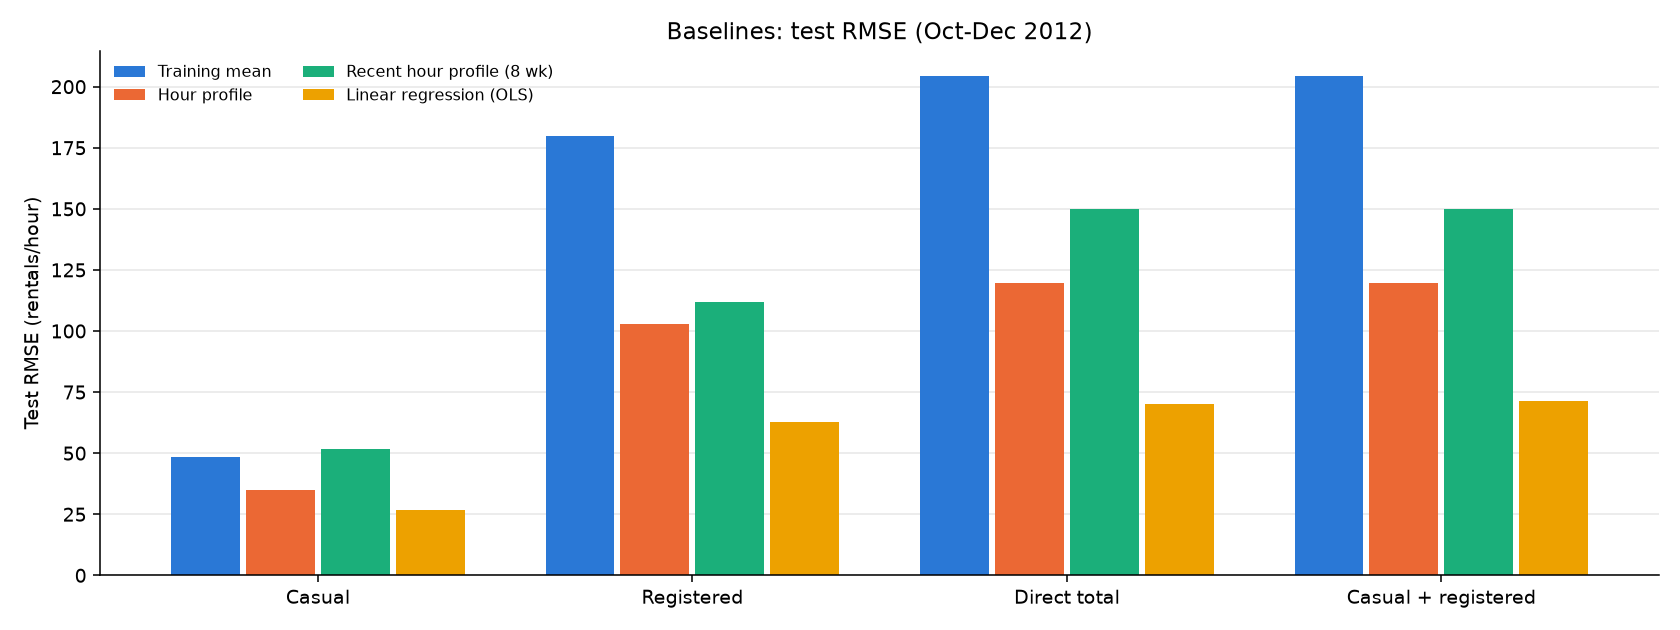

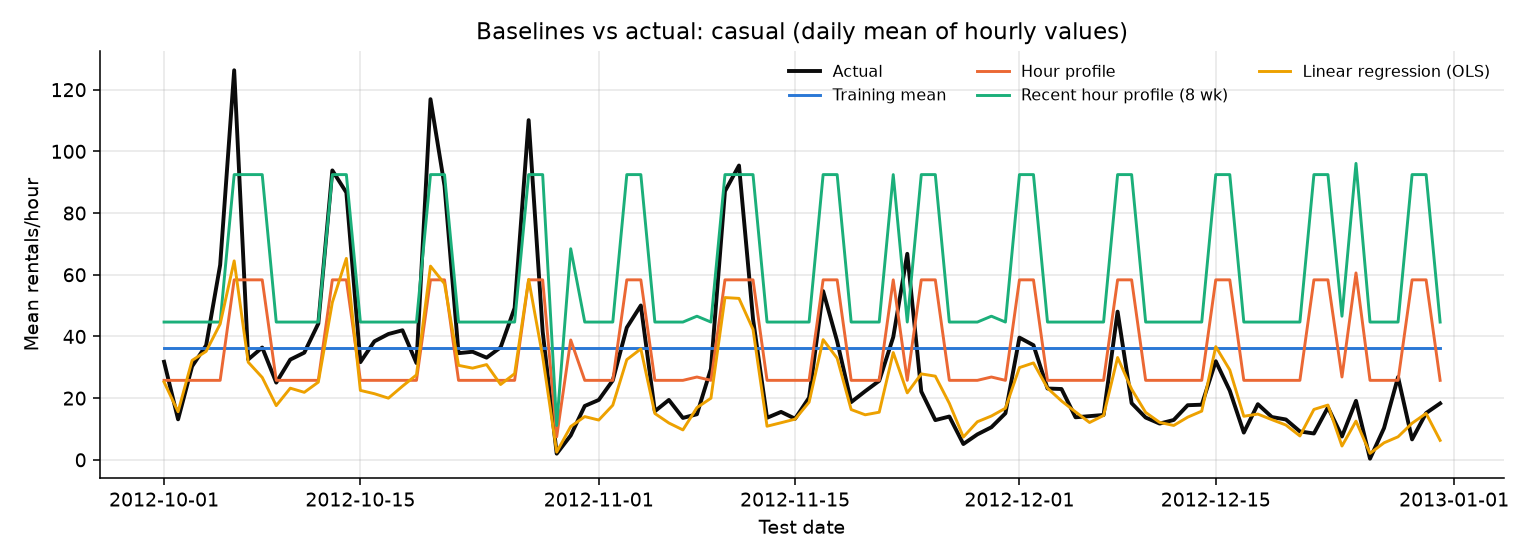

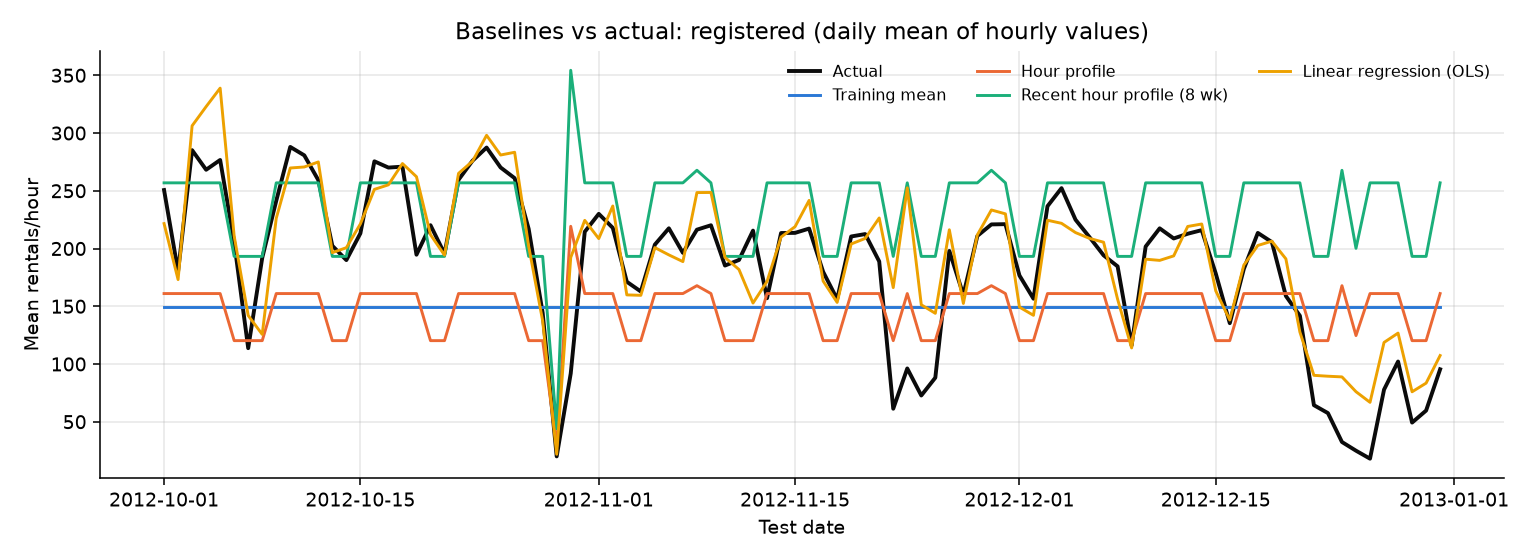

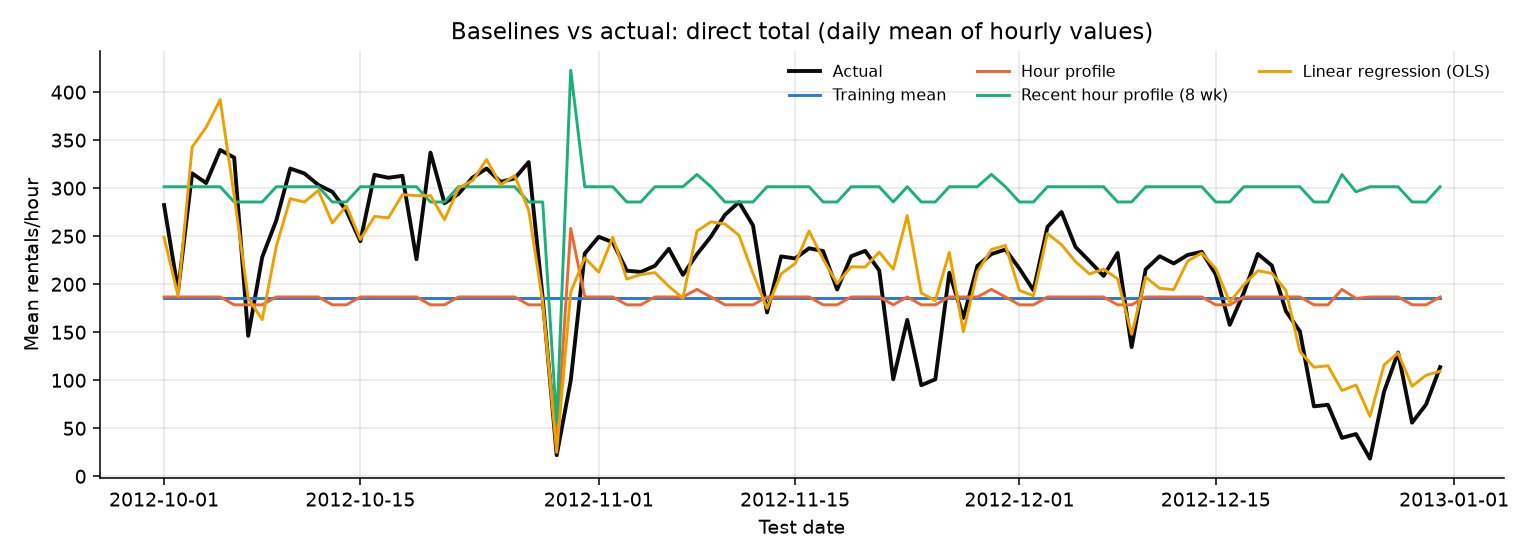

In [4]:
display(Image(filename=str(OUTPUT / "baseline_test_rmse.png")))
for target in ("casual", "registered", "cnt"):
    display(Image(filename=str(OUTPUT / f"baseline_daily_{target}.png")))

**Reading the daily plots:** the hour profile has the right daily shape but no seasonal level, so it overshoots in November–December. The recent profile is anchored to August–September demand. It scores well in cross-validation because training folds sit inside a growth period, but it is the worst baseline on the cold-season test months. That gap between CV and test is the seasonal-shift caveat from the EDA (Section 5.5): a good cross-validation score here does not guarantee a good score on the autumn–winter test period.